In [14]:
import time

from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import cv2
import numpy as np

from ultralytics import YOLO
import torch

Проверяем имеющийся датасет

In [2]:
ROOT = Path("../")
DATASET_PATH = ROOT / "data/tobacco_yolo/"

print(DATASET_PATH)

..\data\tobacco_yolo


Пример генерации

In [5]:
# Очистка памяти GPU перед запуском
torch.cuda.empty_cache()

model = YOLO(ROOT / "best.pt")
# results = model.predict(
#     source="C:\yolo_project\screen",
#     imgsz=640,
#     conf=0.4,
#     device=0,
#     half=True,
#     fuse=True,	
#     save=True,
#     project="weed_results",
#     name="final_run",
#     exist_ok=True
# )


0: 192x320 33 weeds, 6.5ms
Speed: 0.7ms preprocess, 6.5ms inference, 16.8ms postprocess per image at shape (1, 3, 192, 320)


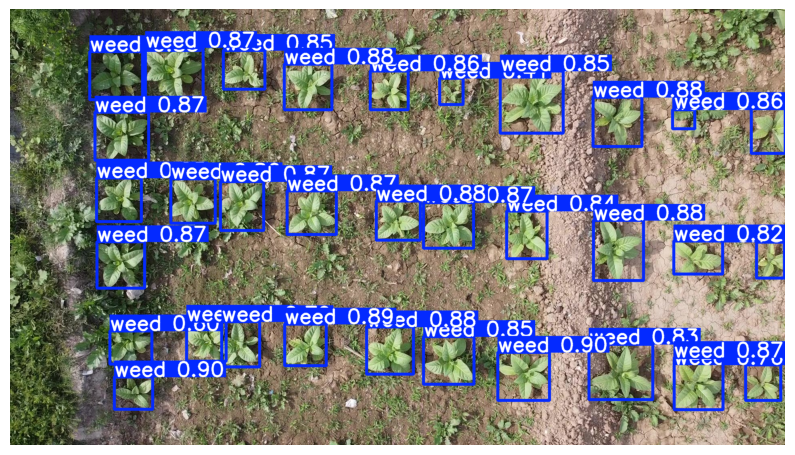

In [8]:

results = model([DATASET_PATH / "images" / "00a357bc-17.jpg"])  # return a list of Results objects

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    obb = result.obb  # Oriented boxes object for OBB outputs
    # result.show()  # display to screen
    annotated_img_point = result.plot()
    annotated_img_point = cv2.cvtColor(annotated_img_point, cv2.COLOR_BGR2RGB)

    # Отображаем результат
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img_point)
    plt.axis("off")
    plt.show()


0: 192x320 33 weeds, 4.5ms
Speed: 0.6ms preprocess, 4.5ms inference, 16.2ms postprocess per image at shape (1, 3, 192, 320)


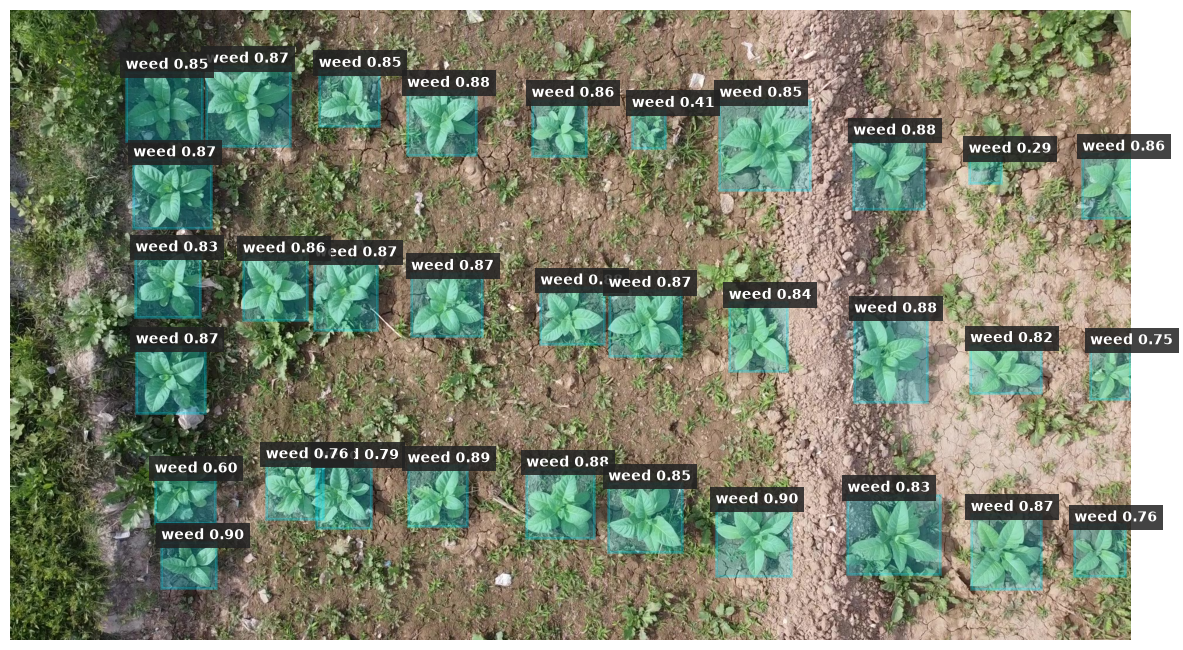

In [11]:
results = model([DATASET_PATH / "images" / "00a357bc-17.jpg"])

for result in results:
    img = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    if result.boxes is not None:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            cls_id = int(box.cls[0])
            conf = float(box.conf[0])

            class_name = result.names[cls_id]

            # Your own custom style
            color = "#00E5FF"

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor=color,
                facecolor=color,
                alpha=0.25
            )

            ax.add_patch(rect)

            # Label with background
            ax.text(
                x1,
                max(0, y1 - 5),
                f"{class_name} {conf:.2f}",
                color="white",
                fontsize=10,
                fontweight="bold",
                bbox={
                    "facecolor": "#222222",
                    "alpha": 0.85,
                    "edgecolor": "none",
                    "pad": 4
                }
            )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

Проверка fps

In [17]:
img = cv2.imread(str(DATASET_PATH / "images" / "00a357bc-17.jpg"))

def synchronize():
    if str(model.device).startswith("cuda"):
        torch.cuda.synchronize(model.device)

# Warmup
for _ in range(200):
    model.predict(img, verbose=False)

synchronize()

latencies = []

# Benchmark
for _ in range(2000):
    synchronize()
    start = time.perf_counter()

    results = model.predict(
        img,
        verbose=False,
        imgsz=640,
        conf=0.5
    )

    # Simulate decision-making from detections
    boxes = results[0].boxes

    if boxes is not None and len(boxes) > 0:
        # Example: make a decision based on class IDs
        detected_classes = boxes.cls.cpu().numpy()
        obstacle_detected = np.any(detected_classes == 0)
    else:
        obstacle_detected = False

    synchronize()
    latencies.append(
        (time.perf_counter() - start) * 1000
    )

latencies = np.array(latencies)

print(f"Mean latency: {latencies.mean():.2f} ms")
print(f"Median latency: {np.median(latencies):.2f} ms")
print(f"P95 latency: {np.percentile(latencies, 95):.2f} ms")
print(f"P99 latency: {np.percentile(latencies, 99):.2f} ms")
print(f"Estimated FPS: {1000 / latencies.mean():.2f}")

Mean latency: 22.33 ms
Median latency: 22.26 ms
P95 latency: 23.42 ms
P99 latency: 24.07 ms
Estimated FPS: 44.78


In [18]:
def synthetic_stream(image, fps=30):
    interval = 1.0 / fps
    next_frame_time = time.perf_counter()

    while True:
        now = time.perf_counter()

        if now < next_frame_time:
            time.sleep(next_frame_time - now)

        yield image.copy()

        next_frame_time += interval

        # Skip missed slots instead of accumulating delay
        now = time.perf_counter()
        if next_frame_time < now:
            next_frame_time = now

In [ ]:
img = cv2.imread(
    str(DATASET_PATH / "images" / "00a357bc-17.jpg")
)

stream = synthetic_stream(img, fps=30)

start = time.perf_counter()
frame_count = 0

for frame in stream:
    results = model.predict(
        frame,
        verbose=False,
        imgsz=640
    )

    result = results[0]

    # Example decision logic
    boxes = result.boxes
    obstacle_detected = boxes is not None and len(boxes) > 0

    action = "STOP" if obstacle_detected else "MOVE"

    frame_count += 1

    if frame_count >= 300:
        break

elapsed = time.perf_counter() - start

print(f"Actual processing FPS: {frame_count / elapsed:.2f}")

In [19]:
import queue
import threading

from ultralytics.data.loaders import LoadStreams, SourceTypes


class SyntheticStream(LoadStreams):
    def __init__(self, image, fps=30):
        # Do not call super().__init__():
        # that would try to open a real camera/URL.
        if image is None or fps <= 0:
            raise ValueError("Provide a valid image and positive FPS")

        self.image = image
        self.fps = [fps]
        self.bs = 1
        self.mode = "stream"
        self.count = -1
        self.running = True
        self.source_type = SourceTypes(stream=True)

        self.frames = queue.Queue(maxsize=1)
        self.stop_event = threading.Event()

        self.thread = threading.Thread(
            target=self._produce,
            daemon=True
        )
        self.thread.start()

    def _produce(self):
        interval = 1 / self.fps[0]
        next_time = time.perf_counter()

        while not self.stop_event.is_set():
            if self.stop_event.wait(
                max(0, next_time - time.perf_counter())
            ):
                break

            frame = self.image.copy()

            # Keep only the newest frame
            if self.frames.full():
                try:
                    self.frames.get_nowait()
                except queue.Empty:
                    pass

            self.frames.put_nowait(frame)

            next_time += interval

            if next_time < time.perf_counter():
                next_time = time.perf_counter()

    def __iter__(self):
        return self

    def __next__(self):
        if self.stop_event.is_set():
            raise StopIteration

        frame = self.frames.get(timeout=5)
        self.count += 1

        return ["synthetic.jpg"], [frame], [""]

    def __len__(self):
        return self.bs

    def close(self):
        self.stop_event.set()
        self.running = False
        self.thread.join()

Processed: 300 frames
Effective FPS: 128.06


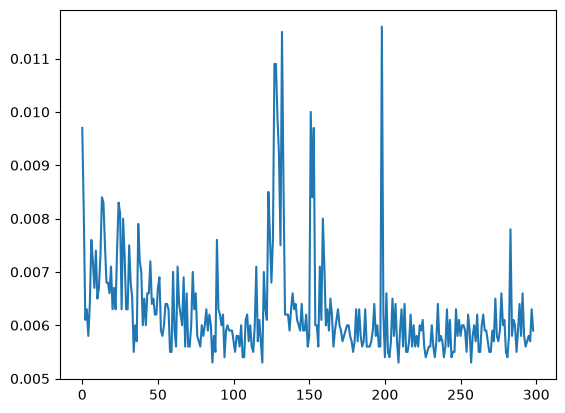

: 

In [ ]:
img = cv2.imread(
    str(DATASET_PATH / "images" / "00a357bc-17.jpg")
)

stream = SyntheticStream(img, fps=300)

latencies = []

try:
    results = model.predict(
        source=stream,
        stream=True,
        imgsz=640,
        verbose=False,
        save=False,
        show=False
    )

    start = time.perf_counter()
    frame_count = 0

    for result in results:
        start_2 = time.perf_counter()
        boxes = result.boxes

        # Robot logic
        obstacle_detected = boxes is not None and len(boxes) > 0
        action = "STOP" if obstacle_detected else "MOVE"

        frame_count += 1

        if frame_count >= 300:
            break

        latencies.append((time.perf_counter() - start_2) * 1000)

    elapsed = time.perf_counter() - start

    print(f"Processed: {frame_count} frames")
    print(f"Effective FPS: {frame_count / elapsed:.2f}")

finally:
    stream.close()

plt.plot(latencies)